# Indian License Plate Recognition — Training (PP-OCRv4 vs PP-OCRv5)
**Assignment deliverable 1.** Real fine-tuning and validation; no fabricated results.

Use **cropped plate images with verified transcription labels**. The Kaggle source is optional: if its annotations lack text, prepare a `labels.csv` with columns `filename,text` and provide cropped plate images. This notebook stops instead of training on unlabeled or invented labels. Train/validation = 80/20.

**Important:** PaddleOCR repository configs and checkpoint compatibility can change. This notebook inspects available configs and requires verified model-specific pretrained checkpoints. Models are recognition-only; full-vehicle detection is handled separately in inference.

**Run in Google Colab with GPU enabled.** Upload the original Kaggle `archive.zip` before running the dataset cells. Training takes substantial time. The executed outputs below are retained from the original run. Best weights, configs and plate crops were saved in `PaddleOCR_Indian_Plates_Backup.zip` (downloaded separately). **Note:** `.pdparams` training checkpoints are not the same as exported Paddle inference artifacts; export is not demonstrated in this notebook.

In [ ]:
!nvidia-smi

Tue Oct 27 06:36:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'archive.zip', 'sample_data']


In [ ]:
import zipfile
import os

zip_path = "/content/archive.zip"
extract_path = "/content/indian_plate_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
import os
from collections import Counter

dataset_path = "/content/indian_plate_dataset"

file_types = Counter()
image_count = 0

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        ext = os.path.splitext(file)[1].lower()
        file_types[ext] += 1

        if ext in [".jpg", ".jpeg", ".png"]:
            image_count += 1

print("Total images:", image_count)
print("File types:", dict(file_types))

print("\nDataset folders:")
for item in os.listdir(dataset_path)[:20]:
    print(item)

Total images: 1698
File types: {'.xml': 1697, '.jpg': 1339, '.png': 53, '.jpeg': 306, '.txt': 1}

Dataset folders:
video_images
google_images
State-wise_OLX


In [ ]:
import os
import xml.etree.ElementTree as ET

dataset_path = "/content/indian_plate_dataset"

xml_files = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith(".xml"):
            xml_files.append(os.path.join(root, file))

print("Total XML files:", len(xml_files))

for xml_file in xml_files[:3]:
    print("\n" + "=" * 50)
    print("XML File:", os.path.basename(xml_file))

    try:
        tree = ET.parse(xml_file)
        root = tree.getroot()
        ET.indent(tree, space="  ")
        print(ET.tostring(root, encoding="unicode")[:4000])
    except Exception as e:
        print("Error:", e)

Total XML files: 1697

XML File: video12_80.xml
<annotation>
  <folder>video_screenshots</folder>
  <filename>video12_80.jpg</filename>
  <path>C:\Users\Siri\Desktop\BARC_ki_padhai\Project\video_screenshots\video12_80.jpg</path>
  <source>
    <database>Unknown</database>
  </source>
  <size>
    <width>940</width>
    <height>1011</height>
    <depth>3</depth>
  </size>
  <segmented>0</segmented>
  <object>
    <name>MH02BG9542</name>
    <pose>Unspecified</pose>
    <truncated>0</truncated>
    <difficult>0</difficult>
    <bndbox>
      <xmin>49</xmin>
      <ymin>624</ymin>
      <xmax>306</xmax>
      <ymax>699</ymax>
    </bndbox>
  </object>
</annotation>

XML File: video5_130.xml
<annotation>
  <folder>video_screenshots</folder>
  <filename>video5_130.jpg</filename>
  <path>C:\Users\Siri\Desktop\BARC_ki_padhai\Project\video_screenshots\video5_130.jpg</path>
  <source>
    <database>Unknown</database>
  </source>
  <size>
    <width>920</width>
    <height>543</height>
    <dept

In [ ]:
import os
import re
import csv
import cv2
import xml.etree.ElementTree as ET

dataset_path = "/content/indian_plate_dataset"
output_path = "/content/plate_crops"

os.makedirs(output_path, exist_ok=True)

records = []
skipped = 0

for root_dir, dirs, files in os.walk(dataset_path):
    for file in files:
        if not file.lower().endswith(".xml"):
            continue

        xml_path = os.path.join(root_dir, file)

        try:
            tree = ET.parse(xml_path)
            annotation = tree.getroot()

            image_name = annotation.findtext("filename")
            if not image_name:
                skipped += 1
                continue

            image_path = os.path.join(root_dir, image_name)

            if not os.path.isfile(image_path):
                skipped += 1
                continue

            image = cv2.imread(image_path)
            if image is None:
                skipped += 1
                continue

            height, width = image.shape[:2]

            for index, obj in enumerate(annotation.findall("object")):
                plate_text = obj.findtext("name", "")
                plate_text = re.sub(
                    r"[^A-Z0-9]", "", plate_text.upper()
                )

                box = obj.find("bndbox")

                if not plate_text or box is None:
                    skipped += 1
                    continue

                xmin = max(0, int(float(box.findtext("xmin"))))
                ymin = max(0, int(float(box.findtext("ymin"))))
                xmax = min(width, int(float(box.findtext("xmax"))))
                ymax = min(height, int(float(box.findtext("ymax"))))

                if xmax <= xmin or ymax <= ymin:
                    skipped += 1
                    continue

                crop = image[ymin:ymax, xmin:xmax]

                crop_name = (
                    f"{os.path.splitext(file)[0]}_{index}.jpg"
                )
                crop_path = os.path.join(output_path, crop_name)

                if cv2.imwrite(crop_path, crop):
                    records.append([crop_path, plate_text])
                else:
                    skipped += 1

        except Exception as error:
            skipped += 1
            print("Skipped:", file, str(error))

labels_path = "/content/plate_labels.csv"

with open(labels_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["filename", "text"])
    writer.writerows(records)

print("Total cropped plates:", len(records))
print("Skipped entries:", skipped)
print("Labels saved to:", labels_path)
print("Sample labels:", records[:5])

Total cropped plates: 1695
Skipped entries: 2
Labels saved to: /content/plate_labels.csv
Sample labels: [['/content/plate_crops/video12_80_0.jpg', 'MH02BG9542'], ['/content/plate_crops/video5_130_0.jpg', 'MH03CS6266'], ['/content/plate_crops/video5_100_0.jpg', 'MH03CS6266'], ['/content/plate_crops/video4_2030_0.jpg', 'MH02DS3099'], ['/content/plate_crops/video11_4070_0.jpg', 'MH03DU5196']]


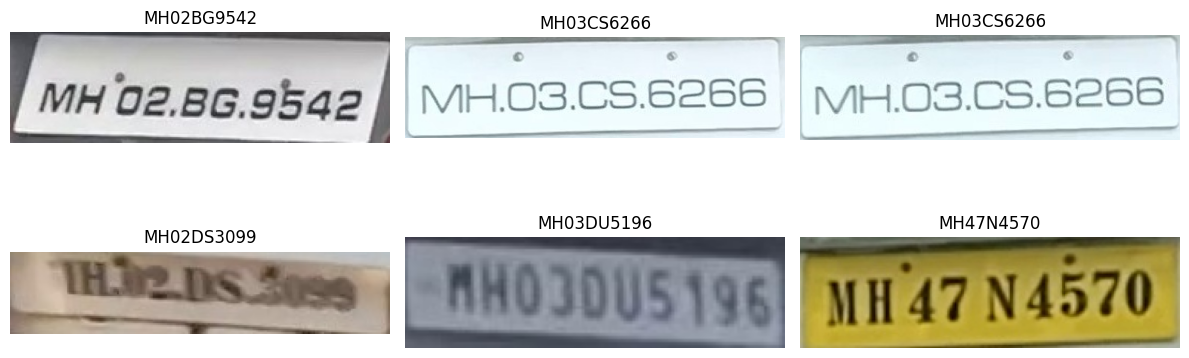

In [ ]:
import matplotlib.pyplot as plt
import cv2

sample_records = records[:6]

fig, axes = plt.subplots(2, 3, figsize=(12, 5))

for ax, (image_path, label) in zip(axes.flat, sample_records):
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(label)
    ax.axis("off")

for ax in axes.flat[len(sample_records):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

df = pd.read_csv("/content/plate_labels.csv", dtype=str)

df = df.dropna(subset=["filename", "text"])
df = df[df["filename"].apply(os.path.isfile)]
df = df[df["text"].str.fullmatch(r"[A-Z0-9]+")]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(df, groups=df["text"])
)

train_df = df.iloc[train_idx].copy()
val_df = df.iloc[val_idx].copy()

assert set(train_df["text"]).isdisjoint(set(val_df["text"]))

print("Total valid crops:", len(df))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Training percentage:", round(len(train_df) / len(df) * 100, 2))
print("Validation percentage:", round(len(val_df) / len(df) * 100, 2))
print("Duplicate plate leakage: None")

Total valid crops: 1695
Training images: 1365
Validation images: 330
Training percentage: 80.53
Validation percentage: 19.47
Duplicate plate leakage: None


In [ ]:
output_dir = "/content/ocr_dataset"
os.makedirs(output_dir, exist_ok=True)

def save_labels(dataframe, filename):
    with open(filename, "w", encoding="utf-8") as f:
        for _, row in dataframe.iterrows():
            f.write(
                f"{row['filename']}\t{row['text']}\n"
            )

train_file = os.path.join(output_dir, "train.txt")
val_file = os.path.join(output_dir, "val.txt")

save_labels(train_df, train_file)
save_labels(val_df, val_file)

print("Training labels:", train_file)
print("Validation labels:", val_file)

print("\nSample training labels:")
with open(train_file, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().strip())

Training labels: /content/ocr_dataset/train.txt
Validation labels: /content/ocr_dataset/val.txt

Sample training labels:
/content/plate_crops/video12_80_0.jpg	MH02BG9542
/content/plate_crops/video5_130_0.jpg	MH03CS6266
/content/plate_crops/video5_100_0.jpg	MH03CS6266
/content/plate_crops/video4_2030_0.jpg	MH02DS3099
/content/plate_crops/video11_4070_0.jpg	MH03DU5196


In [ ]:
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Unique training plates:", train_df["text"].nunique())
print("Unique validation plates:", val_df["text"].nunique())

print("\nTraining file exists:", os.path.exists(train_file))
print("Validation file exists:", os.path.exists(val_file))

Training samples: 1365
Validation samples: 330
Unique training plates: 785
Unique validation plates: 197

Training file exists: True
Validation file exists: True


In [ ]:
import os

if not os.path.isdir("/content/PaddleOCR"):
    !git clone https://github.com/PaddlePaddle/PaddleOCR.git /content/PaddleOCR

print("PaddleOCR repository ready")

Cloning into '/content/PaddleOCR'...
remote: Enumerating objects: 353900, done.
remote: Counting objects: 100% (1215/1215), done.
remote: Compressing objects: 100% (180/180), done.
remote: Total 353900 (delta 1126), reused 1035 (delta 1035), pack-reused 352685 (from 2)
Receiving objects: 100% (353900/353900), 1.87 GiB | 29.75 MiB/s, done.
Resolving deltas: 100% (279849/279849), done.
PaddleOCR repository ready


In [ ]:
import glob

config_dir = "/content/PaddleOCR/configs/rec"

v4_configs = sorted(glob.glob(
    f"{config_dir}/PP-OCRv4/*.yml"
))

v5_configs = sorted(glob.glob(
    f"{config_dir}/PP-OCRv5/*.yml"
))

print("PP-OCRv4 configurations:")
for path in v4_configs:
    print(os.path.basename(path))

print("\nPP-OCRv5 configurations:")
for path in v5_configs:
    print(os.path.basename(path))

print("\nPython version:")
!python --version

print("\nPaddlePaddle installation:")
!python -m pip show paddlepaddle-gpu

PP-OCRv4 configurations:
PP-OCRv4_mobile_rec.yml
PP-OCRv4_mobile_rec_ampO2_ultra.yml
PP-OCRv4_mobile_rec_distillation.yml
PP-OCRv4_mobile_rec_fp32_ultra.yml
PP-OCRv4_server_rec.yml
PP-OCRv4_server_rec_ampO2_ultra.yml
PP-OCRv4_server_rec_doc.yml
PP-OCRv4_server_rec_fp32_ultra.yml
ch_PP-OCRv4_rec_svtr_large.yml
en_PP-OCRv4_mobile_rec.yml

PP-OCRv5 configurations:
PP-OCRv5_mobile_rec.yml
PP-OCRv5_server_rec.yml

Python version:
Python 3.13.16

PaddlePaddle installation:


In [ ]:
%pip install paddlepaddle-gpu==3.3.0 -i https://www.paddlepaddle.org.cn/packages/stable/cu130/

Looking in indexes: https://www.paddlepaddle.org.cn/packages/stable/cu130/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 GB 4.1 MB/s  0:02:49
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 8.9 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.6/348.6 MB 7.9 MB/s  0:00:42
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 420.9/420.9 MB 8.7 MB/s  0:00:47
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 8.8 MB/s  0:00:19
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 195.3/195.3 MB 8.4 MB/s  0:00:23
  Attempting uninstall: nvidia-cusparselt-cu13
    Found existing installation: nvidia-cusparselt-cu13 0.8.0
    Uninstalling nvidia-cusparselt-cu13-0.8.0:
      Successfully uninstalled nvidia-cusparselt-cu13-0.8.0
  Attempting uninstall: opt_einsum
    Found existing installation: opt_einsum 3.4.0
    Uninstalling opt_einsum-3.4.0:
      Successfully uninstalled opt_einsum-3.4.0
  Attempting uninstall: nvidia-nccl-cu13
    Found existing installation: n

In [ ]:
import paddle

print("PaddlePaddle version:", paddle.__version__)
print("CUDA compiled:", paddle.is_compiled_with_cuda())
print("Available GPUs:", paddle.device.cuda.device_count())

paddle.utils.run_check()


/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


PaddlePaddle version: 3.3.0
CUDA compiled: True
Available GPUs: 1
Running verify PaddlePaddle program ... 


/usr/local/lib/python3.13/dist-packages/paddle/pir/math_op_patch.py:241: UserWarning: Tensor do not have 'place' interface for pir graph mode, try not to use it. None will be returned.
  warnings.warn(


PaddlePaddle works well on 1 GPU.
PaddlePaddle is installed successfully! Let's start deep learning with PaddlePaddle now.


In [ ]:
%cd /content/PaddleOCR

%pip install -r requirements.txt

/content/PaddleOCR
Ignoring lmdb: markers 'python_version < "3.9"' don't match your environment
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 22.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.1/572.1 kB 22.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 86.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [lmdb]


In [ ]:
import paddle
import yaml
import cv2
import numpy as np

print("PaddlePaddle:", paddle.__version__)
print("GPU available:", paddle.is_compiled_with_cuda())
print("GPU count:", paddle.device.cuda.device_count())

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

print("Training script exists:",
      __import__("os").path.exists("/content/PaddleOCR/tools/train.py"))

print("PP-OCRv4 config exists:",
      __import__("os").path.exists(
          "/content/PaddleOCR/configs/rec/PP-OCRv4/en_PP-OCRv4_mobile_rec.yml"
      ))

print("PP-OCRv5 config exists:",
      __import__("os").path.exists(
          "/content/PaddleOCR/configs/rec/PP-OCRv5/PP-OCRv5_mobile_rec.yml"
      ))

PaddlePaddle: 3.3.0
GPU available: True
GPU count: 1
OpenCV: 5.0.0
NumPy: 2.1.3
Training script exists: True
PP-OCRv4 config exists: True
PP-OCRv5 config exists: True


In [ ]:
import yaml

configs = {
    "PP-OCRv4": "/content/PaddleOCR/configs/rec/PP-OCRv4/en_PP-OCRv4_mobile_rec.yml",
    "PP-OCRv5": "/content/PaddleOCR/configs/rec/PP-OCRv5/PP-OCRv5_mobile_rec.yml"
}

for model_name, config_path in configs.items():
    with open(config_path, "r") as f:
        config = yaml.safe_load(f)

    print("\n" + "=" * 50)
    print(model_name)
    print("=" * 50)

    print("Algorithm:",
          config.get("Architecture", {}).get("algorithm"))

    print("Backbone:",
          config.get("Architecture", {}).get("Backbone"))

    print("Head:",
          config.get("Architecture", {}).get("Head"))

    print("Character dictionary:",
          config.get("Global", {}).get("character_dict_path"))

    print("Pretrained model:",
          config.get("Global", {}).get("pretrained_model"))

    print("Epochs:",
          config.get("Global", {}).get("epoch_num"))

    print("Batch size:",
          config.get("Train", {}).get("loader", {}).get("batch_size_per_card"))


PP-OCRv4
Algorithm: SVTR_LCNet
Backbone: {'name': 'PPLCNetV3', 'scale': 0.95}
Head: {'name': 'MultiHead', 'head_list': [{'CTCHead': {'Neck': {'name': 'svtr', 'dims': 120, 'depth': 2, 'hidden_dims': 120, 'kernel_size': [1, 3], 'use_guide': True}, 'Head': {'fc_decay': 1e-05}}}, {'NRTRHead': {'nrtr_dim': 384, 'max_text_length': 25}}]}
Character dictionary: ppocr/utils/en_dict.txt
Pretrained model: None
Epochs: 50
Batch size: 96

PP-OCRv5
Algorithm: SVTR_LCNet
Backbone: {'name': 'PPLCNetV3', 'scale': 0.95}
Head: {'name': 'MultiHead', 'head_list': [{'CTCHead': {'Neck': {'name': 'svtr', 'dims': 120, 'depth': 2, 'hidden_dims': 120, 'kernel_size': [1, 3], 'use_guide': True}, 'Head': {'fc_decay': 1e-05}}}, {'NRTRHead': {'nrtr_dim': 384, 'max_text_length': 25}}]}
Character dictionary: ./ppocr/utils/dict/ppocrv5_dict.txt
Pretrained model: None
Epochs: 75
Batch size: 128


In [ ]:
import os
import string

dictionary_path = "/content/PaddleOCR/ppocr/utils/indian_plate_dict.txt"

characters = string.digits + string.ascii_uppercase

with open(dictionary_path, "w", encoding="utf-8") as f:
    for character in characters:
        f.write(character + "\n")

print("Dictionary saved:", dictionary_path)
print("Total characters:", len(characters))
print("Characters:", characters)

Dictionary saved: /content/PaddleOCR/ppocr/utils/indian_plate_dict.txt
Total characters: 36
Characters: 0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ


In [ ]:
import pandas as pd

df = pd.read_csv("/content/plate_labels.csv", dtype=str)

allowed_characters = set(characters)

invalid_labels = []

for label in df["text"].dropna():
    if not set(label).issubset(allowed_characters):
        invalid_labels.append(label)

print("Total labels:", len(df))
print("Invalid labels:", len(invalid_labels))
print("Examples:", invalid_labels[:10])

Total labels: 1695
Invalid labels: 0
Examples: []


In [ ]:
import yaml

for model_name, config_path in configs.items():
    with open(config_path, "r") as f:
        config = yaml.safe_load(f)

    print("\n" + "=" * 55)
    print(model_name)
    print("=" * 55)

    print("Pretrained model:", config["Global"].get("pretrained_model"))
    print("Save model directory:", config["Global"].get("save_model_dir"))

    print("\nTraining dataset configuration:")
    print("Data directory:", config["Train"]["dataset"].get("data_dir"))
    print("Label files:", config["Train"]["dataset"].get("label_file_list"))

    print("\nEvaluation dataset configuration:")
    print("Data directory:", config["Eval"]["dataset"].get("data_dir"))
    print("Label files:", config["Eval"]["dataset"].get("label_file_list"))

    print("\nImage shape:")
    for transform in config["Train"]["dataset"]["transforms"]:
        if "RecResizeImg" in transform:
            print(transform["RecResizeImg"])
        if "RecConAug" in transform:
            print("Augmentation:", transform["RecConAug"])


PP-OCRv4
Pretrained model: None
Save model directory: ./output/rec_ppocr_v4

Training dataset configuration:
Data directory: ./train_data/
Label files: ['./train_data/train_list.txt']

Evaluation dataset configuration:
Data directory: ./train_data
Label files: ['./train_data/val_list.txt']

Image shape:
Augmentation: {'prob': 0.5, 'ext_data_num': 2, 'image_shape': [48, 320, 3], 'max_text_length': 25}

PP-OCRv5
Pretrained model: None
Save model directory: ./output/PP-OCRv5_mobile_rec

Training dataset configuration:
Data directory: ./train_data/
Label files: ['./train_data/train_list.txt']

Evaluation dataset configuration:
Data directory: ./train_data
Label files: ['./train_data/val_list.txt']

Image shape:
Augmentation: {'prob': 0.5, 'ext_data_num': 2, 'image_shape': [48, 320, 3], 'max_text_length': 25}


In [ ]:
import os

dictionary_files = [
    "/content/PaddleOCR/ppocr/utils/en_dict.txt",
    "/content/PaddleOCR/ppocr/utils/dict/ppocrv5_dict.txt",
    "/content/PaddleOCR/ppocr/utils/indian_plate_dict.txt"
]

for path in dictionary_files:
    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            chars = [line.strip() for line in f if line.strip()]

        print(os.path.basename(path), ":", len(chars), "characters")
        print("First 50:", "".join(chars[:50]))
    else:
        print("Missing:", path)

en_dict.txt : 94 characters
First 50: 0123456789:;<=>?@ABCDEFGHIJKLMNOPQRSTUVWXYZ[\]^_`a
ppocrv5_dict.txt : 18382 characters
First 50: 一乙二十丁厂七卜八人入儿匕几九刁了刀力乃又三干于亏工土士才下寸大丈与万上小口山巾千乞川亿个夕久么勺凡
indian_plate_dict.txt : 36 characters
First 50: 0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ


In [ ]:
import yaml
from pprint import pprint

for model_name, config_path in configs.items():
    with open(config_path, "r") as f:
        config = yaml.safe_load(f)

    print("\n" + "=" * 55)
    print(model_name)
    print("=" * 55)

    print("\nLoss configuration:")
    pprint(config.get("Loss"))

    print("\nPost-processing:")
    pprint(config.get("PostProcess"))

    print("\nTraining transforms:")
    pprint(config["Train"]["dataset"]["transforms"])

    print("\nEvaluation transforms:")
    pprint(config["Eval"]["dataset"]["transforms"])

    print("\nTraining data loader:")
    pprint(config["Train"]["loader"])


PP-OCRv4

Loss configuration:
{'loss_config_list': [{'CTCLoss': None}, {'NRTRLoss': None}],
 'name': 'MultiLoss'}

Post-processing:
{'name': 'CTCLabelDecode'}

Training transforms:
[{'DecodeImage': {'channel_first': False, 'img_mode': 'BGR'}},
 {'RecConAug': {'ext_data_num': 2,
                'image_shape': [48, 320, 3],
                'max_text_length': 25,
                'prob': 0.5}},
 {'RecAug': None},
 {'MultiLabelEncode': {'gtc_encode': 'NRTRLabelEncode'}},
 {'KeepKeys': {'keep_keys': ['image',
                             'label_ctc',
                             'label_gtc',
                             'length',
                             'valid_ratio']}}]

Evaluation transforms:
[{'DecodeImage': {'channel_first': False, 'img_mode': 'BGR'}},
 {'MultiLabelEncode': {'gtc_encode': 'NRTRLabelEncode'}},
 {'RecResizeImg': {'image_shape': [3, 48, 320]}},
 {'KeepKeys': {'keep_keys': ['image',
                             'label_ctc',
                             'label_gtc',
   

In [ ]:
import os
import yaml
import copy

config_output_dir = "/content/indian_plate_configs"
os.makedirs(config_output_dir, exist_ok=True)

model_configs = {}

for model_name, original_path in configs.items():

    with open(original_path, "r") as f:
        config = yaml.safe_load(f)

    config = copy.deepcopy(config)

    # Dataset paths
    config["Train"]["dataset"]["data_dir"] = "/"
    config["Train"]["dataset"]["label_file_list"] = [
        "/content/ocr_dataset/train.txt"
    ]

    config["Eval"]["dataset"]["data_dir"] = "/"
    config["Eval"]["dataset"]["label_file_list"] = [
        "/content/ocr_dataset/val.txt"
    ]

    # Indian number plate dictionary
    config["Global"]["character_dict_path"] = (
        "/content/PaddleOCR/ppocr/utils/indian_plate_dict.txt"
    )

    config["Global"]["use_space_char"] = False
    config["Global"]["max_text_length"] = 25

    # GPU-friendly settings
    config["Train"]["loader"]["batch_size_per_card"] = 16
    config["Eval"]["loader"]["batch_size_per_card"] = 16

    config["Train"]["loader"]["num_workers"] = 2
    config["Eval"]["loader"]["num_workers"] = 2

    # Initial fine-tuning settings
    config["Global"]["epoch_num"] = 20
    config["Global"]["save_epoch_step"] = 5
    config["Global"]["eval_batch_step"] = [0, 100]

    config["Global"]["save_model_dir"] = (
        f"/content/output/{model_name}"
    )

    output_file = os.path.join(
        config_output_dir,
        f"{model_name}_indian_plate.yml"
    )

    with open(output_file, "w") as f:
        yaml.safe_dump(config, f, sort_keys=False)

    model_configs[model_name] = output_file

    print(model_name, "configuration saved:", output_file)

PP-OCRv4 configuration saved: /content/indian_plate_configs/PP-OCRv4_indian_plate.yml
PP-OCRv5 configuration saved: /content/indian_plate_configs/PP-OCRv5_indian_plate.yml


In [ ]:
for model_name, config_path in model_configs.items():

    with open(config_path, "r") as f:
        config = yaml.safe_load(f)

    print("\nModel:", model_name)
    print("Dictionary:", config["Global"]["character_dict_path"])
    print("Train labels:", config["Train"]["dataset"]["label_file_list"])
    print("Validation labels:", config["Eval"]["dataset"]["label_file_list"])
    print("Batch size:", config["Train"]["loader"]["batch_size_per_card"])
    print("Epochs:", config["Global"]["epoch_num"])
    print("Output:", config["Global"]["save_model_dir"])


Model: PP-OCRv4
Dictionary: /content/PaddleOCR/ppocr/utils/indian_plate_dict.txt
Train labels: ['/content/ocr_dataset/train.txt']
Validation labels: ['/content/ocr_dataset/val.txt']
Batch size: 16
Epochs: 20
Output: /content/output/PP-OCRv4

Model: PP-OCRv5
Dictionary: /content/PaddleOCR/ppocr/utils/indian_plate_dict.txt
Train labels: ['/content/ocr_dataset/train.txt']
Validation labels: ['/content/ocr_dataset/val.txt']
Batch size: 16
Epochs: 20
Output: /content/output/PP-OCRv5


In [ ]:
import requests
import re

url = (
    "https://raw.githubusercontent.com/PaddlePaddle/"
    "PaddleOCR/main/docs/version3.x/module_usage/"
    "text_recognition.en.md"
)

response = requests.get(url, timeout=30)
response.raise_for_status()

lines = response.text.splitlines()

for model in ["en_PP-OCRv4_mobile_rec", "PP-OCRv5_mobile_rec"]:
    print("\n" + "=" * 60)
    print(model)
    print("=" * 60)

    matches = [
        line for line in lines
        if re.search(rf"(?<![\w-]){re.escape(model)}(?![\w-])", line)
        and ("http" in line or ".tar" in line)
    ]

    for line in matches[:5]:
        print(line[:1500])

    if not matches:
        print("No matching download links found.")


en_PP-OCRv4_mobile_rec
No matching download links found.

PP-OCRv5_mobile_rec
No matching download links found.


In [ ]:
import requests
import re

url = (
    "https://raw.githubusercontent.com/PaddlePaddle/"
    "PaddleOCR/main/docs/version3.x/module_usage/"
    "text_recognition.en.md"
)

response = requests.get(url, timeout=30)
response.raise_for_status()

models = [
    "en_PP-OCRv4_mobile_rec",
    "PP-OCRv5_mobile_rec",
    "en_PP-OCRv5_mobile_rec"
]

for model in models:
    print("\n" + "=" * 60)
    print("MODEL:", model)
    print("=" * 60)

    for line in response.text.splitlines():
        if line.startswith("|") and re.match(
            rf"^\|\s*{re.escape(model)}\s*\|", line
        ):
            links = re.findall(
                r"\[([^\]]+)\]\((https?://[^)]+)\)",
                line
            )

            for label, link in links:
                print(label, ":", link)

            if not links:
                print("Model found, but no Markdown links extracted.")


MODEL: en_PP-OCRv4_mobile_rec

MODEL: PP-OCRv5_mobile_rec

MODEL: en_PP-OCRv5_mobile_rec


In [ ]:
import requests
import re

url = (
    "https://raw.githubusercontent.com/PaddlePaddle/"
    "PaddleOCR/main/docs/version3.x/module_usage/"
    "text_recognition.en.md"
)

response = requests.get(url, timeout=30)
response.raise_for_status()

models = [
    "en_PP-OCRv4_mobile_rec",
    "PP-OCRv5_mobile_rec",
    "en_PP-OCRv5_mobile_rec"
]

print("HTTP status:", response.status_code)
print("Document length:", len(response.text))

for model in models:
    print("\n" + "=" * 60)
    print(model)
    print("=" * 60)

    matching_lines = [
        line for line in response.text.splitlines()
        if model in line
        and ("http" in line or "](" in line)
    ]

    if not matching_lines:
        print("No matching row found.")
        continue

    for line in matching_lines[:3]:
        print("Documentation row:", line[:1000])

        links = re.findall(
            r"https?://[^\s)<>\"']+",
            line
        )

        for link in links:
            print("URL:", link)

HTTP status: 200
Document length: 55745

en_PP-OCRv4_mobile_rec
Documentation row: en_PP-OCRv4_mobile_rec_infer.tar">Inference Model</a>/<a href="https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/en_PP-OCRv4_mobile_rec_pretrained.pdparams">Pretrained Model</a></td>
URL: https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/en_PP-OCRv4_mobile_rec_pretrained.pdparams
Documentation row: en_PP-OCRv4_mobile_rec_infer.tar">Inference Model</a>/<a href="https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/en_PP-OCRv4_mobile_rec_pretrained.pdparams">Pretrained Model</a></td>
URL: https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/en_PP-OCRv4_mobile_rec_pretrained.pdparams

PP-OCRv5_mobile_rec
Documentation row: PP-OCRv5_mobile_rec_infer.tar">Inference Model</a>/<a href="https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/PP-OCRv5_mobile_rec_pretrained.pdparams">Pretrained

In [ ]:
import os
import requests

checkpoint_dir = "/content/pretrained_models"
os.makedirs(checkpoint_dir, exist_ok=True)

checkpoints = {
    "PP-OCRv4": (
        "https://paddle-model-ecology.bj.bcebos.com/"
        "paddlex/official_pretrained_model/"
        "en_PP-OCRv4_mobile_rec_pretrained.pdparams"
    ),
    "PP-OCRv5": (
        "https://paddle-model-ecology.bj.bcebos.com/"
        "paddlex/official_pretrained_model/"
        "en_PP-OCRv5_mobile_rec_pretrained.pdparams"
    )
}

checkpoint_paths = {}

for model_name, url in checkpoints.items():
    filename = url.split("/")[-1]
    destination = os.path.join(checkpoint_dir, filename)

    if not os.path.isfile(destination):
        print("Downloading:", model_name)

        with requests.get(url, stream=True, timeout=120) as response:
            response.raise_for_status()

            with open(destination, "wb") as f:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)

    checkpoint_paths[model_name] = destination

    print(
        model_name,
        "| File:", destination,
        "| Size:",
        round(os.path.getsize(destination) / (1024 * 1024), 2),
        "MB"
    )

Downloading: PP-OCRv4
PP-OCRv4 | File: /content/pretrained_models/en_PP-OCRv4_mobile_rec_pretrained.pdparams | Size: 65.67 MB
Downloading: PP-OCRv5
PP-OCRv5 | File: /content/pretrained_models/en_PP-OCRv5_mobile_rec_pretrained.pdparams | Size: 66.82 MB


In [ ]:
import paddle

for model_name, checkpoint_path in checkpoint_paths.items():
    print("\n" + "=" * 55)
    print(model_name)
    print("=" * 55)

    try:
        state_dict = paddle.load(checkpoint_path)

        print("Checkpoint loaded successfully")
        print("Total parameter tensors:", len(state_dict))

        print("\nFirst 5 parameter names:")
        for name in list(state_dict.keys())[:5]:
            print(name, state_dict[name].shape)

    except Exception as error:
        print("Checkpoint loading error:", str(error))


PP-OCRv4
Checkpoint loaded successfully
Total parameter tensors: 968

First 5 parameter names:
backbone.conv1.conv.weight paddle.Size([16, 3, 3, 3])
backbone.conv1.bn.weight paddle.Size([16])
backbone.conv1.bn.bias paddle.Size([16])
backbone.conv1.bn._mean paddle.Size([16])
backbone.conv1.bn._variance paddle.Size([16])

PP-OCRv5
Checkpoint loaded successfully
Total parameter tensors: 968

First 5 parameter names:
backbone.conv1.conv.weight paddle.Size([16, 3, 3, 3])
backbone.conv1.bn.weight paddle.Size([16])
backbone.conv1.bn.bias paddle.Size([16])
backbone.conv1.bn._mean paddle.Size([16])
backbone.conv1.bn._variance paddle.Size([16])


## 1. Install dependencies and check GPU

In [ ]:
import os
import sys
import yaml
import paddle

os.chdir("/content/PaddleOCR")

if "/content/PaddleOCR" not in sys.path:
    sys.path.insert(0, "/content/PaddleOCR")

from ppocr.modeling.architectures import build_model
from ppocr.postprocess import build_post_process

for model_name, config_path in model_configs.items():

    print("\n" + "=" * 60)
    print("MODEL:", model_name)
    print("=" * 60)

    with open(config_path, "r") as f:
        config = yaml.safe_load(f)

    post_process = build_post_process(
        config["PostProcess"],
        config["Global"]
    )

    char_count = len(post_process.character)
    print("Decoder character count:", char_count)

    architecture = config["Architecture"].copy()

    if architecture["algorithm"] == "Distillation":
        for key in architecture["Models"]:
            architecture["Models"][key]["Head"]["out_channels"] = char_count

    elif architecture["Head"]["name"] == "MultiHead":
        architecture["Head"]["out_channels_list"] = {
            "CTCLabelDecode": char_count,
            "NRTRLabelDecode": char_count + 3
        }

    else:
        architecture["Head"]["out_channels"] = char_count

    model = build_model(architecture)

    current_weights = model.state_dict()
    pretrained_weights = paddle.load(checkpoint_paths[model_name])

    matching = []
    mismatched = []
    missing = []

    for name, tensor in current_weights.items():

        if name not in pretrained_weights:
            missing.append(name)

        elif list(tensor.shape) == list(pretrained_weights[name].shape):
            matching.append(name)

        else:
            mismatched.append(
                (
                    name,
                    list(tensor.shape),
                    list(pretrained_weights[name].shape)
                )
            )

    print("Matching tensors:", len(matching))
    print("Shape mismatches:", len(mismatched))
    print("Missing tensors:", len(missing))

    print("\nFirst 10 mismatched tensors:")
    for item in mismatched[:10]:
        print(item)

    del model

Skipping import of the encryption module.


/content/PaddleOCR/ppocr/postprocess/rec_postprocess.py:1239: SyntaxWarning: invalid escape sequence '\W'
  noletter = "[\W_^\d]"
/content/PaddleOCR/ppocr/postprocess/rec_postprocess.py:1479: SyntaxWarning: invalid escape sequence '\W'
  noletter = "[\W_^\d]"
/content/PaddleOCR/ppocr/postprocess/rec_postprocess.py:1523: SyntaxWarning: invalid escape sequence '\W'
  noletter = "[\W_^\d]"



MODEL: PP-OCRv4
Decoder character count: 37


/content/PaddleOCR/ppocr/modeling/heads/rec_nrtr_head.py:371: SyntaxWarning: invalid escape sequence '\d'
  \text{MultiHead}(Q, K, V) = \text{Concat}(head_1,\dots,head_h)W^O


Matching tensors: 964
Shape mismatches: 4
Missing tensors: 0

First 10 mismatched tensors:
('head.ctc_head.fc.weight', [120, 37], [120, 97])
('head.ctc_head.fc.bias', [37], [97])
('head.gtc_head.embedding.embedding.weight', [41, 384], [101, 384])
('head.gtc_head.tgt_word_prj.weight', [384, 41], [384, 101])

MODEL: PP-OCRv5
Decoder character count: 37
Matching tensors: 964
Shape mismatches: 4
Missing tensors: 0

First 10 mismatched tensors:
('head.ctc_head.fc.weight', [120, 37], [120, 438])
('head.ctc_head.fc.bias', [37], [438])
('head.gtc_head.embedding.embedding.weight', [41, 384], [442, 384])
('head.gtc_head.tgt_word_prj.weight', [384, 41], [384, 442])


In [ ]:
import os
import sys
import yaml
import paddle

os.chdir("/content/PaddleOCR")

if "/content/PaddleOCR" not in sys.path:
    sys.path.insert(0, "/content/PaddleOCR")

from ppocr.modeling.architectures import build_model
from ppocr.postprocess import build_post_process

adapted_dir = "/content/adapted_checkpoints"
os.makedirs(adapted_dir, exist_ok=True)

adapted_paths = {}

for model_name, config_path in model_configs.items():

    with open(config_path, "r") as f:
        config = yaml.safe_load(f)

    post_process = build_post_process(
        config["PostProcess"],
        config["Global"]
    )

    char_count = len(post_process.character)

    architecture = config["Architecture"].copy()

    architecture["Head"]["out_channels_list"] = {
        "CTCLabelDecode": char_count,
        "NRTRLabelDecode": char_count + 3
    }

    model = build_model(architecture)

    current_weights = model.state_dict()
    pretrained_weights = paddle.load(checkpoint_paths[model_name])

    adapted_weights = {}
    reused = 0
    initialized = 0

    for name, tensor in current_weights.items():

        if (
            name in pretrained_weights
            and list(tensor.shape) == list(pretrained_weights[name].shape)
        ):
            adapted_weights[name] = pretrained_weights[name]
            reused += 1
        else:
            adapted_weights[name] = tensor
            initialized += 1

    model.set_state_dict(adapted_weights)

    output_path = os.path.join(
        adapted_dir,
        f"{model_name}_indian_plate.pdparams"
    )

    paddle.save(model.state_dict(), output_path)

    adapted_paths[model_name] = output_path

    print("\nModel:", model_name)
    print("Reused tensors:", reused)
    print("Initialized tensors:", initialized)
    print("Saved:", output_path)

    del model



Model: PP-OCRv4
Reused tensors: 964
Initialized tensors: 4
Saved: /content/adapted_checkpoints/PP-OCRv4_indian_plate.pdparams

Model: PP-OCRv5
Reused tensors: 964
Initialized tensors: 4
Saved: /content/adapted_checkpoints/PP-OCRv5_indian_plate.pdparams


In [ ]:
for model_name, path in adapted_paths.items():

    weights = paddle.load(path)

    print("\nModel:", model_name)
    print("Checkpoint exists:", os.path.isfile(path))
    print("Parameter tensors:", len(weights))
    print(
        "Checkpoint size:",
        round(os.path.getsize(path) / (1024 * 1024), 2),
        "MB"
    )


Model: PP-OCRv4
Checkpoint exists: True
Parameter tensors: 968
Checkpoint size: 65.47 MB

Model: PP-OCRv5
Checkpoint exists: True
Parameter tensors: 968
Checkpoint size: 65.47 MB


In [ ]:
import yaml

for model_name, config_path in model_configs.items():

    with open(config_path, "r") as f:
        config = yaml.safe_load(f)

    # Load our adapted pretrained checkpoint
    config["Global"]["pretrained_model"] = adapted_paths[model_name]

    # Training settings
    config["Global"]["epoch_num"] = 20
    config["Global"]["save_epoch_step"] = 5
    config["Global"]["eval_batch_step"] = [0, 100]

    # GPU-friendly batch sizes
    config["Train"]["loader"]["batch_size_per_card"] = 16
    config["Eval"]["loader"]["batch_size_per_card"] = 16

    config["Train"]["loader"]["num_workers"] = 2
    config["Eval"]["loader"]["num_workers"] = 2

    # Adjust sampler batch size if present
    train_sampler = config["Train"].get("sampler", {})

    if "first_bs" in train_sampler:
        train_sampler["first_bs"] = 16

    # Lower learning rate for fine-tuning
    config["Optimizer"]["lr"]["learning_rate"] = 0.0001

    with open(config_path, "w") as f:
        yaml.safe_dump(config, f, sort_keys=False)

    print("\nModel:", model_name)
    print("Checkpoint:", config["Global"]["pretrained_model"])
    print("Epochs:", config["Global"]["epoch_num"])
    print("Batch size:", config["Train"]["loader"]["batch_size_per_card"])
    print("Learning rate:", config["Optimizer"]["lr"]["learning_rate"])
    print("Sampler:", config["Train"].get("sampler"))


Model: PP-OCRv4
Checkpoint: /content/adapted_checkpoints/PP-OCRv4_indian_plate.pdparams
Epochs: 20
Batch size: 16
Learning rate: 0.0001
Sampler: {'name': 'MultiScaleSampler', 'scales': [[320, 32], [320, 48], [320, 64]], 'first_bs': 16, 'fix_bs': False, 'divided_factor': [8, 16], 'is_training': True}

Model: PP-OCRv5
Checkpoint: /content/adapted_checkpoints/PP-OCRv5_indian_plate.pdparams
Epochs: 20
Batch size: 16
Learning rate: 0.0001
Sampler: {'name': 'MultiScaleSampler', 'scales': [[320, 32], [320, 48], [320, 64]], 'first_bs': 16, 'fix_bs': False, 'divided_factor': [8, 16], 'is_training': True}


In [ ]:
import os
import yaml

config_path = "/content/indian_plate_configs/PP-OCRv4_indian_plate.yml"
test_config_path = "/content/indian_plate_configs/PP-OCRv4_test.yml"

with open(config_path, "r") as f:
    config = yaml.safe_load(f)

config["Global"]["epoch_num"] = 1
config["Global"]["save_model_dir"] = "/content/output/PP-OCRv4_test"
config["Global"]["eval_batch_step"] = [0, 20]

with open(test_config_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("One-epoch test configuration created.")

One-epoch test configuration created.


In [ ]:
%cd /content/PaddleOCR

!python tools/train.py -c /content/indian_plate_configs/PP-OCRv4_test.yml

/content/PaddleOCR
/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Skipping import of the encryption module.
[2026/10/27 07:20:46] ppocr INFO: Architecture : 
[2026/10/27 07:20:46] ppocr INFO:     Backbone : 
[2026/10/27 07:20:46] ppocr INFO:         name : PPLCNetV3
[2026/10/27 07:20:46] ppocr INFO:         scale : 0.95
[2026/10/27 07:20:46] ppocr INFO:     Head : 
[2026/10/27 07:20:46] ppocr INFO:         head_list : 
[2026/10/27 07:20:46] ppocr INFO:             CTCHead : 
[2026/10/27 07:20:46] ppocr INFO:                 Head : 
[2026/10/27 07:20:46] ppocr INFO:                     fc_decay : 1e-05
[2026/10/27 07:20:46] ppocr INFO:                 Neck : 
[2026/10/27 07:20:46] ppocr INFO:                     dep

In [ ]:
import yaml

config_path = "/content/indian_plate_configs/PP-OCRv4_indian_plate.yml"

with open(config_path, "r") as f:
    config = yaml.safe_load(f)

print("Optimizer:")
print(yaml.dump(config["Optimizer"], sort_keys=False))

print("Training sampler:")
print(yaml.dump(config["Train"].get("sampler"), sort_keys=False))

print("Global settings:")
for key in [
    "epoch_num",
    "pretrained_model",
    "max_text_length",
    "character_dict_path",
    "use_space_char",
    "eval_batch_step"
]:
    print(key, ":", config["Global"].get(key))

Optimizer:
name: Adam
beta1: 0.9
beta2: 0.999
lr:
  name: Cosine
  learning_rate: 0.0001
  warmup_epoch: 5
regularizer:
  name: L2
  factor: 3.0e-05

Training sampler:
name: MultiScaleSampler
scales:
- - 320
  - 32
- - 320
  - 48
- - 320
  - 64
first_bs: 16
fix_bs: false
divided_factor:
- 8
- 16
is_training: true

Global settings:
epoch_num : 20
pretrained_model : /content/adapted_checkpoints/PP-OCRv4_indian_plate.pdparams
max_text_length : 25
character_dict_path : /content/PaddleOCR/ppocr/utils/indian_plate_dict.txt
use_space_char : False
eval_batch_step : [0, 100]


In [ ]:
import yaml

for model_name, config_path in model_configs.items():

    with open(config_path, "r") as f:
        config = yaml.safe_load(f)

    config["Optimizer"]["lr"]["warmup_epoch"] = 1

    # Keep the same training settings for both models
    config["Global"]["epoch_num"] = 20
    config["Global"]["eval_batch_step"] = [0, 100]

    with open(config_path, "w") as f:
        yaml.safe_dump(config, f, sort_keys=False)

    print(
        model_name,
        "| Warmup:",
        config["Optimizer"]["lr"]["warmup_epoch"],
        "| Epochs:",
        config["Global"]["epoch_num"]
    )


PP-OCRv4 | Warmup: 1 | Epochs: 20
PP-OCRv5 | Warmup: 1 | Epochs: 20


In [ ]:
%cd /content/PaddleOCR

!python tools/train.py -c /content/indian_plate_configs/PP-OCRv4_indian_plate.yml

/content/PaddleOCR
/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Skipping import of the encryption module.
[2026/10/27 07:24:08] ppocr INFO: Architecture : 
[2026/10/27 07:24:08] ppocr INFO:     Backbone : 
[2026/10/27 07:24:08] ppocr INFO:         name : PPLCNetV3
[2026/10/27 07:24:08] ppocr INFO:         scale : 0.95
[2026/10/27 07:24:08] ppocr INFO:     Head : 
[2026/10/27 07:24:08] ppocr INFO:         head_list : 
[2026/10/27 07:24:08] ppocr INFO:             CTCHead : 
[2026/10/27 07:24:08] ppocr INFO:                 Head : 
[2026/10/27 07:24:08] ppocr INFO:                     fc_decay : 1e-05
[2026/10/27 07:24:08] ppocr INFO:                 Neck : 
[2026/10/27 07:24:08] ppocr INFO:                     dep

In [ ]:
import os
import yaml

v4_best = "/content/output/PP-OCRv4/best_accuracy.pdparams"
v5_config_path = "/content/indian_plate_configs/PP-OCRv5_indian_plate.yml"

print("PP-OCRv4 best checkpoint exists:", os.path.isfile(v4_best))

if os.path.isfile(v4_best):
    print(
        "PP-OCRv4 checkpoint size:",
        round(os.path.getsize(v4_best) / (1024 * 1024), 2),
        "MB"
    )

with open(v5_config_path, "r") as f:
    config = yaml.safe_load(f)

print("\nPP-OCRv5 configuration:")
print("Epochs:", config["Global"]["epoch_num"])
print("Pretrained checkpoint:", config["Global"]["pretrained_model"])
print("Warmup epochs:", config["Optimizer"]["lr"]["warmup_epoch"])
print("Learning rate:", config["Optimizer"]["lr"]["learning_rate"])
print("Batch size:", config["Train"]["loader"]["batch_size_per_card"])
print("Training labels:", config["Train"]["dataset"]["label_file_list"])
print("Validation labels:", config["Eval"]["dataset"]["label_file_list"])

PP-OCRv4 best checkpoint exists: True
PP-OCRv4 checkpoint size: 65.46 MB

PP-OCRv5 configuration:
Epochs: 20
Pretrained checkpoint: /content/adapted_checkpoints/PP-OCRv5_indian_plate.pdparams
Warmup epochs: 1
Learning rate: 0.0001
Batch size: 16
Training labels: ['/content/ocr_dataset/train.txt']
Validation labels: ['/content/ocr_dataset/val.txt']


In [ ]:
%cd /content/PaddleOCR

!python tools/train.py -c /content/indian_plate_configs/PP-OCRv5_indian_plate.yml

/content/PaddleOCR
/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Skipping import of the encryption module.
[2026/10/27 08:04:03] ppocr INFO: Architecture : 
[2026/10/27 08:04:03] ppocr INFO:     Backbone : 
[2026/10/27 08:04:03] ppocr INFO:         name : PPLCNetV3
[2026/10/27 08:04:03] ppocr INFO:         scale : 0.95
[2026/10/27 08:04:03] ppocr INFO:     Head : 
[2026/10/27 08:04:03] ppocr INFO:         head_list : 
[2026/10/27 08:04:03] ppocr INFO:             CTCHead : 
[2026/10/27 08:04:03] ppocr INFO:                 Head : 
[2026/10/27 08:04:03] ppocr INFO:                     fc_decay : 1e-05
[2026/10/27 08:04:03] ppocr INFO:                 Neck : 
[2026/10/27 08:04:03] ppocr INFO:                     dep

In [ ]:
import os

checkpoints = {
    "PP-OCRv4": "/content/output/PP-OCRv4/best_accuracy.pdparams",
    "PP-OCRv5": "/content/output/PP-OCRv5/best_accuracy.pdparams"
}

for model_name, path in checkpoints.items():
    exists = os.path.isfile(path)
    size = round(os.path.getsize(path) / (1024 * 1024), 2) if exists else 0

    print(model_name)
    print("Checkpoint exists:", exists)
    print("Size:", size, "MB")
    print()

PP-OCRv4
Checkpoint exists: True
Size: 65.46 MB

PP-OCRv5
Checkpoint exists: True
Size: 65.46 MB



In [ ]:
import os
import zipfile
from google.colab import files

backup_zip = "/content/PaddleOCR_Indian_Plates_Backup.zip"

items = {
    "models/PP-OCRv4_best_accuracy.pdparams":
        "/content/output/PP-OCRv4/best_accuracy.pdparams",

    "models/PP-OCRv5_best_accuracy.pdparams":
        "/content/output/PP-OCRv5/best_accuracy.pdparams",

    "configs/PP-OCRv4_indian_plate.yml":
        "/content/indian_plate_configs/PP-OCRv4_indian_plate.yml",

    "configs/PP-OCRv5_indian_plate.yml":
        "/content/indian_plate_configs/PP-OCRv5_indian_plate.yml",

    "labels/train.txt":
        "/content/ocr_dataset/train.txt",

    "labels/val.txt":
        "/content/ocr_dataset/val.txt",

    "indian_plate_dict.txt":
        "/content/PaddleOCR/ppocr/utils/indian_plate_dict.txt",
}

with zipfile.ZipFile(backup_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for name, path in items.items():
        if not os.path.isfile(path):
            raise FileNotFoundError(path)

        z.write(path, arcname=name)
        print("Added:", name)

    # Include cropped training and validation images
    crop_dir = "/content/plate_crops"

    for root, dirs, filenames in os.walk(crop_dir):
        for filename in filenames:
            path = os.path.join(root, filename)
            relative = os.path.relpath(path, crop_dir)
            z.write(path, arcname=os.path.join("plate_crops", relative))

print("\nBackup created successfully!")
print("Backup size:", round(os.path.getsize(backup_zip) / (1024 * 1024), 2), "MB")

files.download(backup_zip)

Added: models/PP-OCRv4_best_accuracy.pdparams
Added: models/PP-OCRv5_best_accuracy.pdparams
Added: configs/PP-OCRv4_indian_plate.yml
Added: configs/PP-OCRv5_indian_plate.yml
Added: labels/train.txt
Added: labels/val.txt
Added: indian_plate_dict.txt

Backup created successfully!
Backup size: 134.05 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Reported validation results

| Model | Best exact-match accuracy (330 validation crops) | Normalized edit similarity |
|---|---:|---:|
| PP-OCRv4 | 56.67% | 92.47% |
| PP-OCRv5 | **82.12%** | **96.55%** |

Both models were trained for 20 epochs; these values reflect their best validation checkpoints. The group-based split reduces registration-text leakage.